# Can similar contracts help us spot mispricing?

Prediction market prices can be read as probabilities. For example, a YES contract that costs 30 cents suggests about a 30% chance of paying out. If a large set of similar 30-cent contracts wins about 30% of the time, those prices are well calibrated.

Becker documents systematic mispricing across the full dataset, even though market prices are well calibrated overall. We build on that finding by looking at a finer grouping level. Rather than treating all contracts as one population or relying only on broad categories, we group contracts with similar subjects, structures, and wording. Our question is: **how does mispricing vary across these smaller groups, and can group membership help us predict pricing errors on held-out events?**

We start with price alone, then add a structural family, and finally add a text-based cluster. We use the same type of model, ridge regression, for all three comparisons. Each comparison has one model fitted across the training data. The pooled model is our main modeling baseline because it has no group information. We also keep the original market price as an uncorrected benchmark: it uses no fitted correction model.

The notebook follows the process from the CSV files to our final results. We first look at the data, build the groups, examine past pricing errors, and then test whether group membership helps. This is a simplified version of our earlier experiment, so its model results will differ from that version.

**Getting started:** run the cells from top to bottom using the project Python environment. All analysis code is included here. The master trade CSV has about 65 million rows, so we use DuckDB to summarize it before modeling. The notebook uses numpy, pandas, scipy, scikit-learn, duckdb, matplotlib, threadpoolctl, and Jupyter. Tables and figures are saved in `output/extension_notebook_simple/`.

## 1. Get familiar with the data

The master CSVs contain market information, trades, and final outcomes. The other market CSVs tell us which events belong to the training, validation, and test sets. We keep these existing splits so that contracts from the same event do not end up on both sides of the evaluation.

We train on the training set and report scores for the other two sets. We do not use validation or test outcomes to fit the models or choose settings. These splits are based on events rather than time, so our results describe performance on held-out events. They do not show that we could have made these predictions 72 hours before an event ended.

In [133]:
from __future__ import annotations

import hashlib
import importlib.metadata
import json
import re
import time
from pathlib import Path
from types import SimpleNamespace

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LogNorm, TwoSlopeNorm
from scipy import sparse
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler, normalize
from threadpoolctl import threadpool_limits

SEED = 340
ALPHA = 10.0  # Fixed regularization; no tuning grid.
BOOTSTRAP = 2000
GROUPING = SimpleNamespace(
    fit_limit=20000, family_fit_limit=1000, distance=0.35, min_similarity=0.75, min_contracts=20, min_events=10
)
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/kalshi_recent_year_csv").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from the repository or one of its subdirectories.")
DATA = ROOT / "data/kalshi_recent_year_csv"
OUTPUT = ROOT / "output/extension_notebook_simple"
OUTPUT.mkdir(parents=True, exist_ok=True)
required = [DATA / f"master/{name}.csv" for name in ["markets", "trades"]] + [
    DATA / f"split/{split}/markets.csv" for split in ["train", "validation", "test"]
]
for path in required:
    if not path.is_file():
        raise FileNotFoundError(path)
(OUTPUT / "run_manifest.json").write_text(json.dumps({"completed": False}) + "\n")
started = time.time()
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "font.size": 10,
    }
)
COLORS = {"Market price": "#606b7a", "Pooled": "#db9850", "Structural": "#438b91", "Structural + NLP": "#7865ad"}
SPLITS = ["train", "validation", "test"]


def show_figure(name: str) -> None:
    """Display a figure in the story and export the same figure for the paper."""
    plt.gcf().tight_layout()
    plt.gcf().savefig(OUTPUT / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

## 2. Decide which contracts belong together

Similar wording does not always mean similar contracts. “Above 80” could describe a temperature, an index value, or a player's score. Before comparing text, we group contracts by **domain, underlying subject, and proposition structure**. For example, `crypto/BTC/above` means a Bitcoin contract asking whether the price will be above a threshold.

The rules below use titles, YES subtitles, and series codes. Prices and final outcomes do not affect these groups. Some categories are unknown because the rules cannot recognize every type of contract.

We keep binary contracts with a title and event ID. We also remove contracts with MVE combination prefixes, since those combine several propositions and are harder to compare with ordinary contracts.

In [134]:
NUMBER = r"-?\d[\d,]*(?:\.\d+)?"


def extract_attributes(row: dict) -> dict:
    """Use observable wording and series codes, never prices or outcomes.

    Series codes are heuristic identifiers, not authoritative categories. Exact
    event IDs track dependence; they are not used as semantic clustering inputs.
    """
    title = row.get("title", "") or ""
    subtitle = row.get("yes_sub_title", "") or ""
    text = f"{title} {subtitle}".strip()
    lower = text.lower()
    series = (row.get("event_ticker", "") or "").split("-")[0].removeprefix("KX")
    domain, underlying, provenance = "unknown", series or "unknown", "series_fallback"
    for keyword, name in [("bitcoin", "BTC"), ("ethereum", "ETH"), ("dogecoin", "DOGE")]:
        if keyword in lower:
            domain, underlying, provenance = "crypto", name, "title_rule"
            break
    if "temp" in lower and ("high" in lower or "low" in lower):
        domain, provenance = "weather", "title_rule"
        # Preserve station/measurement identity rather than pooling different cities.
        underlying = series
    elif "s&p 500" in lower or "nasdaq" in lower:
        domain, underlying, provenance = "equities", "SP500" if "s&p 500" in lower else "NASDAQ100", "title_rule"
    elif re.match(r"(?:NFL|NBA|NCAA|MLB|NHL|WNBA|ATP|WTA|PGA)", series):
        domain, provenance = "sports", "series_rule"
        underlying = re.match(r"NCAAMB|NCAAF|WNBA|NFL|NBA|MLB|NHL|ATP|WTA|PGA", series)
        underlying = underlying.group() if underlying else series
    elif "MENTION" in series:
        domain, provenance = "mentions", "series_rule"

    # Prefer the affirmative subtitle: it often contains the actual proposition.
    proposition = (subtitle or title).lower()
    if "wins by" in lower:
        structure = "spread"
    elif "total points" in lower or "points scored" in lower:
        structure = "total"
    elif re.search(rf"{NUMBER}\s*°?\s*(?:to|–|—)\s*\$?{NUMBER}", proposition):
        structure = "interval"
    elif re.search(r"\b(?:above|over|exceed|greater|at least)\b|>|\d\+", proposition):
        structure = "above"
    elif re.search(r"\b(?:below|under|less|at most)\b|<", proposition):
        structure = "below"
    elif "winner" in lower or re.search(r"\bwin\b", lower):
        structure = "winner"
    else:
        structure = "unknown"
    # Do not pool distinct player-prop mechanisms just because they share a sport.
    if structure == "unknown" or (domain == "sports" and structure in {"above", "below"}):
        underlying = series or "unknown"
    numbers = re.findall(NUMBER, subtitle)
    template = re.sub(NUMBER, "[number]", text.lower())
    return {
        "series": series,
        "domain": domain,
        "underlying": underlying,
        "structure": structure,
        "attribute_source": provenance,
        "threshold_tokens": "|".join(numbers),
        "units": "degrees" if "°" in text or "temp" in lower else "USD" if "$" in text else "unknown",
        "family": f"{domain}/{underlying}/{structure}",
        "text": text,
        "template": template,
        "settlement_source": "unknown",
    }

In [135]:
SEED = 340


COLUMNS = ["ticker", "event_ticker", "market_type", "title", "yes_sub_title", "open_time", "close_time"]


def load_contracts(root: Path) -> tuple[pd.DataFrame, dict]:
    """Read only CSV metadata and preserve supplied event-disjoint splits."""
    frames, counts = [], {}
    for split in ("train", "validation", "test"):
        path = root / "split" / split / "markets.csv"
        frame = pd.read_csv(path, usecols=COLUMNS, dtype=str, keep_default_na=False)
        counts[split] = {"input": len(frame)}
        valid = (
            frame.market_type.eq("binary")
            & ~frame.ticker.str.startswith(("KXMVE", "MVE"))
            & frame.title.str.strip().ne("")
            & frame.event_ticker.str.strip().ne("")
        )
        frame = frame[valid].copy()
        counts[split]["retained"] = len(frame)
        frame["split"] = split
        frames.append(frame)
    contracts = pd.concat(frames, ignore_index=True)
    if contracts.ticker.duplicated().any():
        raise ValueError("Duplicate tickers in supplied splits")
    if contracts.groupby("event_ticker").split.nunique().gt(1).any():
        raise ValueError("Event IDs overlap supplied splits")
    attrs = pd.DataFrame([extract_attributes(row) for row in contracts.to_dict("records")])
    return pd.concat([contracts, attrs], axis=1), counts


def stable_sample(frame: pd.DataFrame, limit: int) -> pd.DataFrame:
    keys = frame.ticker.map(lambda value: hashlib.sha256(f"{SEED}:{value}".encode()).hexdigest())
    return frame.loc[keys.sort_values().index[:limit]]

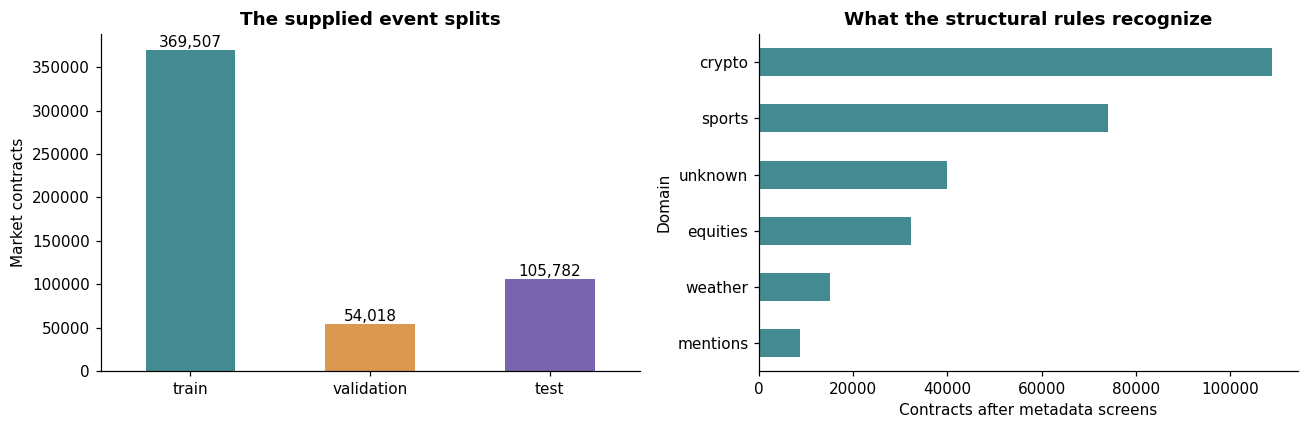

,input,structurally_eligible
train,369507,194378
validation,54018,28271
test,105782,56187


,title,yes_sub_title,family
0,Sacramento St. at UCLA Winner?,UCLA,sports/NCAAMB/winner
1,Sacramento St. at UCLA Winner?,Sacramento St.,sports/NCAAMB/winner
2,Northwestern St. at San Francisco Winner?,San Francisco,sports/NCAAMB/winner
3,Northwestern St. at San Francisco Winner?,Northwestern St.,sports/NCAAMB/winner
4,Idaho St. at Santa Clara Winner?,Santa Clara,sports/NCAAMB/winner
5,Idaho St. at Santa Clara Winner?,Idaho St.,sports/NCAAMB/winner


In [136]:
contracts, attrition = load_contracts(DATA)
input_counts = pd.Series({s: attrition[s]["input"] for s in SPLITS})
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
input_counts.plot.bar(ax=axes[0], color=["#438b91", "#db9850", "#7865ad"], rot=0)
axes[0].set(title="The supplied event splits", ylabel="Market contracts", xlabel="")
for i, value in enumerate(input_counts):
    axes[0].text(i, value, f"{value:,}", ha="center", va="bottom")
contracts.domain.value_counts().sort_values().plot.barh(ax=axes[1], color="#438b91")
axes[1].set(title="What the structural rules recognize", xlabel="Contracts after metadata screens", ylabel="Domain")
show_figure("01_data_landscape")
display(pd.DataFrame(attrition).T.rename(columns={"retained": "structurally_eligible"}))
display(contracts[["title", "yes_sub_title", "family"]].head(6))

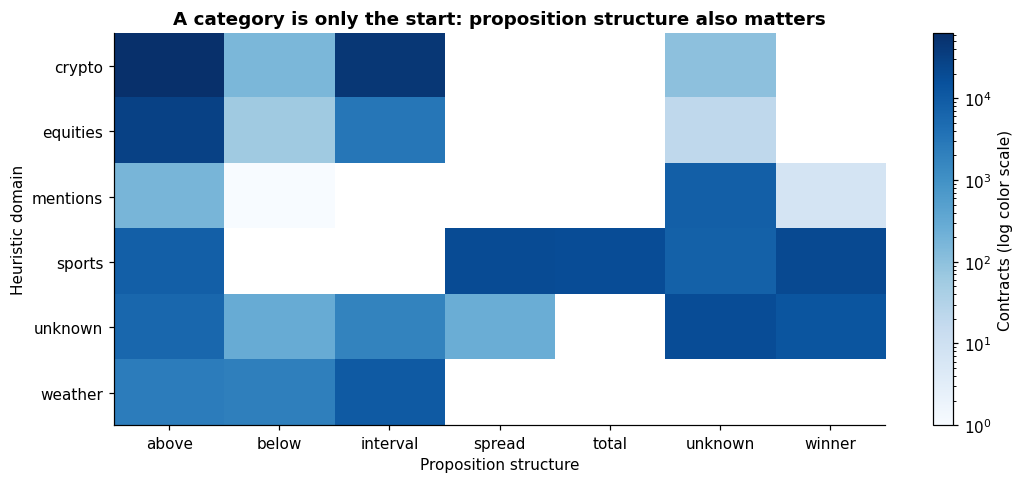

In [137]:
structure_counts = pd.crosstab(contracts.domain, contracts.structure)
fig, ax = plt.subplots(figsize=(10, 4.5))
image = ax.imshow(
    np.ma.masked_equal(structure_counts.to_numpy(), 0),
    norm=LogNorm(vmin=1, vmax=max(2, structure_counts.to_numpy().max())),
    cmap="Blues",
    aspect="auto",
)
ax.set_xticks(range(len(structure_counts.columns)), structure_counts.columns)
ax.set_yticks(range(len(structure_counts.index)), structure_counts.index)
ax.set(
    title="A category is only the start: proposition structure also matters",
    xlabel="Proposition structure",
    ylabel="Heuristic domain",
)
plt.colorbar(image, ax=ax, label="Contracts (log color scale)")
show_figure("02_structural_map")

**Reading the first two figures:** the split chart shows how much data is available for training and evaluation. The domain chart shows which topics our rules recognize; “unknown” means the rules could not assign a domain, not that the contract is invalid.

In the heatmap, darker blue cells contain more contracts. The color scale is logarithmic because some groups are much larger than others. Blank cells have no contracts. Reading across a row shows how one domain includes several proposition types. This is why we use more detail than topic alone when defining a family.

## 3. Use text to find smaller groups within each family

The structural rules give us a starting point, but contracts in the same family can still be worded differently. We use TF-IDF and LSA to represent their text, then cluster contracts within each family. We keep the clustering settings from the earlier implementation:

- **TF-IDF:** represent words and two-word phrases using a fixed sample of up to 20,000 training contracts. Keep up to 20,000 terms.
- **LSA:** reduce those features to at most 64 dimensions, making text similarity easier to work with.
- **Hierarchical clustering:** group a sample of up to 1,000 training contracts per family using average-linkage cosine distance and a cutoff of 0.35.
- **Assignment:** use the resulting cluster centers to assign contracts. A contract needs similarity of at least 0.75, and its group needs at least 20 training contracts from 10 training events.

We learn the text representation and groups using training data only. Validation and test contracts are assigned using those same rules. Contracts without a close enough, supported group stay unassigned. Cluster numbers are just labels; a larger number does not mean more risk or stronger sentiment.

In [138]:
def embed(frame: pd.DataFrame, args) -> np.ndarray:
    """Fit TF-IDF and LSA on the training sample, then transform every split."""
    fit = stable_sample(frame[frame.split.eq("train")], args.fit_limit)
    vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=20000, sublinear_tf=True)
    matrix = vectorizer.fit_transform(fit.text)
    dimensions = min(64, matrix.shape[1] - 1, matrix.shape[0] - 1)
    if dimensions < 2:
        raise ValueError("Insufficient training vocabulary/contracts for LSA")
    svd = TruncatedSVD(n_components=dimensions, random_state=SEED).fit(matrix)
    # Transform batches to bound peak dense memory.
    return np.vstack(
        [
            normalize(svd.transform(vectorizer.transform(frame.text.iloc[start : start + 10000]))).astype("float32")
            for start in range(0, len(frame), 10000)
        ]
    )


def group_contracts(frame: pd.DataFrame, vectors: np.ndarray, args) -> pd.DataFrame:
    """Fit bounded family hierarchies on train; reject distant or unsupported peers.

    Large families use a deterministic training sample to bound quadratic linkage
    memory. Held-out assignment uses frozen centroids, not reclustering. Minimum
    support counts distinct training events rather than correlated contracts.
    """
    result = frame.copy()
    result["cluster"] = ""
    result["status"] = "unseen_family"
    result["similarity"] = np.nan
    for family, members in frame.groupby("family", sort=True):
        train = members[members.split.eq("train")]
        if train.empty:
            continue
        sample = stable_sample(train, args.family_fit_limit)
        ix = sample.index.to_numpy()
        usable = np.linalg.norm(vectors[ix], axis=1) > 0
        ix = ix[usable]
        result.loc[members.index, "status"] = "insufficient_training_support"
        if len(ix) < 2:
            continue
        labels = AgglomerativeClustering(
            n_clusters=None, distance_threshold=args.distance, metric="cosine", linkage="average"
        ).fit_predict(vectors[ix])
        centers = normalize(np.vstack([vectors[ix[labels == label]].mean(axis=0) for label in np.unique(labels)]))
        train_ids = train.index.to_numpy()
        # Determine support using all training contracts, never validation/test counts.
        train_scores = vectors[train_ids] @ centers.T
        nearest = train_scores.argmax(axis=1)
        close = train_scores.max(axis=1) >= args.min_similarity
        supported = []
        for label in range(len(centers)):
            peers = train.iloc[np.flatnonzero((nearest == label) & close)]
            if len(peers) >= args.min_contracts and peers.event_ticker.nunique() >= args.min_events:
                supported.append(label)
        ids = members.index.to_numpy()
        scores = vectors[ids] @ centers.T
        nearest = scores.argmax(axis=1)
        similarity = scores.max(axis=1)
        result.loc[ids, "similarity"] = similarity
        result.loc[ids, "status"] = "distant"
        for label in range(len(centers)):
            mask = (nearest == label) & (similarity >= args.min_similarity)
            chosen = ids[mask]
            if label not in supported:
                result.loc[chosen, "status"] = "insufficient_training_support"
                continue
            result.loc[chosen, "cluster"] = f"{family}/{label:03d}"
            result.loc[chosen, "status"] = "assigned"
    return result

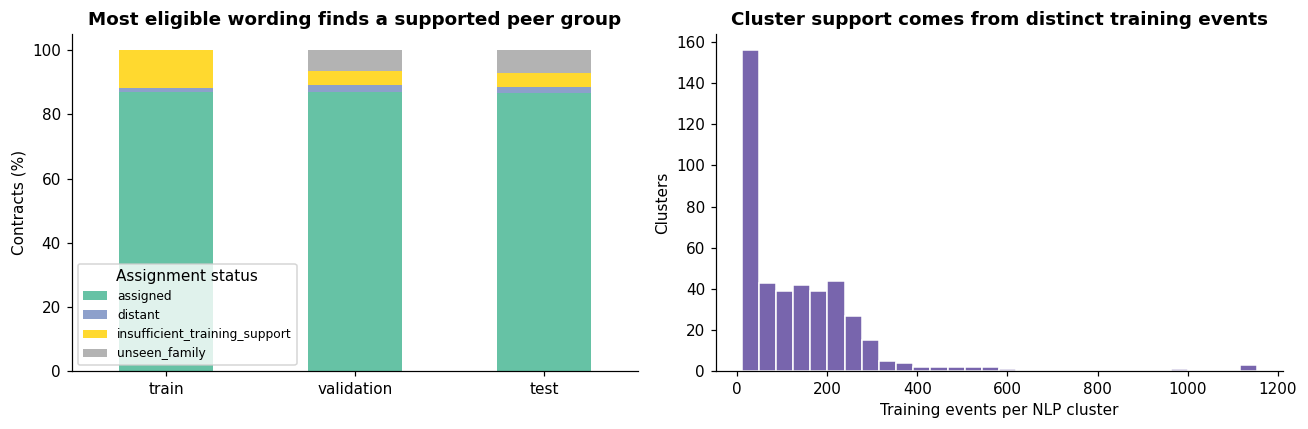

status,assigned,distant,insufficient_training_support,unseen_family
split,,,,
train,169195,2189,22994,0
validation,24547,629,1243,1852
test,48744,1087,2291,4065


In [139]:
with threadpool_limits(limits=2):
    vectors = embed(contracts, GROUPING)
    assignments = group_contracts(contracts, vectors, GROUPING)
ASSIGNMENTS = OUTPUT / "assignments.csv"
assignments.to_csv(ASSIGNMENTS, index=False)
coverage = assignments.groupby(["split", "status"]).size().unstack(fill_value=0).reindex(SPLITS)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
coverage.div(coverage.sum(axis=1), axis=0).mul(100).plot.bar(stacked=True, ax=axes[0], rot=0, colormap="Set2")
axes[0].set(title="Most eligible wording finds a supported peer group", ylabel="Contracts (%)", xlabel="")
axes[0].legend(title="Assignment status", fontsize=8)
training_groups = (
    assignments.query("split == 'train' and status == 'assigned'")
    .groupby("cluster")
    .agg(contracts=("ticker", "nunique"), events=("event_ticker", "nunique"))
)
axes[1].hist(training_groups.events, bins=30, color="#7865ad", edgecolor="white")
axes[1].set(
    title="Cluster support comes from distinct training events",
    xlabel="Training events per NLP cluster",
    ylabel="Clusters",
)
show_figure("03_group_coverage")
display(coverage)
training_groups.to_csv(OUTPUT / "clustering_training_support.csv")

### Check what the text groups look like

The coverage chart above shows the share of contracts assigned to a group in each split. The other colors show why some contracts were left out. Similar assigned shares across splits suggest the rules cover a similar fraction of the data, although that alone does not show that the groups are useful.

The histogram counts distinct training events per cluster. A cluster with many contracts from only a few events has less varied support than its contract count might suggest.

Next, we look inside the largest assigned training family. Each colored point is a contract from one of its six largest clusters, and gray points are from the remaining clusters. We use PCA to show the text vectors in two dimensions. This projection is only for visualization and does not change the groups.

**What to look for:** separated colors suggest differences in wording, while overlap suggests groups that look similar in this view. The full clustering uses more dimensions, so overlap here does not necessarily mean the groups are identical. Read the example titles and YES subtitles below the plot to see what the labels actually represent.

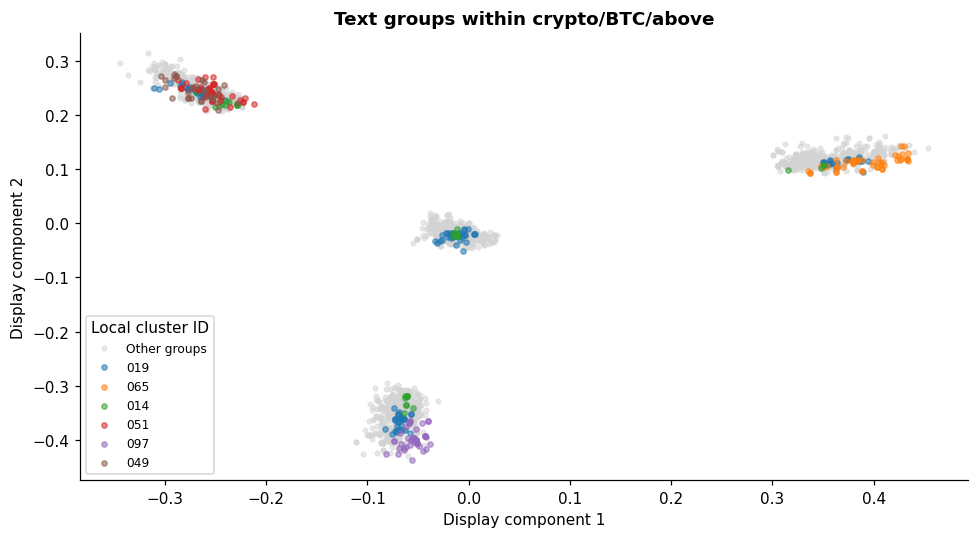

,cluster,title,yes_sub_title,similarity
181744,crypto/BTC/above/019,"Bitcoin price on Dec 12, 2024?","$99,550 or above",0.956047
181752,crypto/BTC/above/019,"Bitcoin price on Dec 12, 2024?","$99,550 or above",0.956047
148459,crypto/BTC/above/065,"Bitcoin price on Mar 9, 2025?","$77,750 or above",0.989058
153234,crypto/BTC/above/065,"Bitcoin price on Mar 7, 2025?","$77,750 or above",0.989058
113330,crypto/BTC/above/014,"Bitcoin price on Jun 5, 2025?","$105,000 or above",0.968855
113340,crypto/BTC/above/014,"Bitcoin price on Jun 5, 2025?","$105,000 or above",0.968855
148428,crypto/BTC/above/051,"Bitcoin price on Mar 9, 2025?","$81,000 or above",0.994218
148436,crypto/BTC/above/051,"Bitcoin price on Mar 9, 2025?","$81,000 or above",0.994218
148453,crypto/BTC/above/097,"Bitcoin price on Mar 9, 2025?","$79,250 or above",0.993576
148457,crypto/BTC/above/097,"Bitcoin price on Mar 9, 2025?","$78,250 or above",0.992469


In [140]:
assigned_train = assignments.query("split == 'train' and status == 'assigned'")
if assigned_train.empty:
    raise ValueError("No supported NLP groups; inspect coverage before continuing.")
example_family = assigned_train.family.value_counts().index[0]
family_rows = assigned_train[assigned_train.family.eq(example_family)]
example = family_rows.sample(min(2000, len(family_rows)), random_state=SEED)
projection = PCA(n_components=2, random_state=SEED).fit(vectors[family_rows.index])
xy = projection.transform(vectors[example.index])
top_groups = family_rows.cluster.value_counts().head(6).index
fig, ax = plt.subplots(figsize=(9, 5))
other = ~example.cluster.isin(top_groups).to_numpy()
ax.scatter(xy[other, 0], xy[other, 1], s=9, color="lightgray", alpha=0.5, label="Other groups")
for cluster in top_groups:
    mask = example.cluster.eq(cluster).to_numpy()
    ax.scatter(xy[mask, 0], xy[mask, 1], s=12, alpha=0.55, label=cluster.rsplit("/", 1)[-1])
ax.set(title=f"Text groups within {example_family}", xlabel="Display component 1", ylabel="Display component 2")
ax.legend(title="Local cluster ID", fontsize=8)
show_figure("04_inside_a_family")
examples = pd.concat([family_rows[family_rows.cluster.eq(c)].nlargest(2, "similarity") for c in top_groups])
with pd.option_context("display.max_colwidth", 100):
    display(examples[["cluster", "title", "yes_sub_title", "similarity"]])
examples[["cluster", "title", "yes_sub_title", "similarity"]].to_csv(OUTPUT / "cluster_examples.csv", index=False)
del vectors

## 4. Build the dataset for prediction

Now we bring in final outcomes. We keep finalized binary markets with YES/NO outcomes and at least $100 in notional volume in the observed trade window. Here, notional is the number of units traded in dollars: the YES and NO positions together cost $1 per unit.

We check for duplicate trade IDs and remove trades with invalid prices, prices that do not add to 100 cents, nonpositive quantities, or invalid taker sides. We also remove the known combination contracts, including explicit multi-award combinations missed by the MVE prefix rule.

To keep the dataset manageable, we summarize trades by contract and execution price. The `n` column records how many executions each row represents. Using `n` as a weight keeps frequently observed prices from being treated the same as prices seen only once. Trades from the same contract still share one final outcome.

We require each NLP cluster to have at least 100 resolved training contracts from 20 training events. All three models use this same supported set of contracts. That gives us a fair comparison, but it also means our results do not describe every Kalshi market.

In [141]:
def quote(path: Path) -> str:
    return "'" + str(path.resolve()).replace("'", "''") + "'"


def extract(data: Path, assignments: Path, output: Path) -> tuple[pd.DataFrame, dict]:
    con = duckdb.connect()
    con.execute("SET threads=4")
    con.execute("SET memory_limit='3GB'")
    con.execute(f"SET temp_directory={quote(output / 'spill')}")
    con.execute(
        f"CREATE VIEW markets AS SELECT * FROM read_csv({quote(data / 'master/markets.csv')}, all_varchar=true)"
    )
    con.execute(f"CREATE VIEW assignments AS SELECT * FROM read_csv({quote(assignments)}, all_varchar=true)")
    for table in ["markets", "assignments"]:
        if con.sql(f"SELECT count(*)-count(DISTINCT ticker) FROM {table}").fetchone()[0]:
            raise ValueError(f"Duplicate tickers in {table}")
    if con.sql(
        "SELECT count(*) FROM assignments a LEFT JOIN markets m USING(ticker) WHERE m.ticker IS NULL"
    ).fetchone()[0]:
        raise ValueError("Assignments contain tickers absent from master CSV")
    con.execute(f"""CREATE VIEW trades AS SELECT trade_id,ticker,taker_side,
        try_cast(yes_price AS BIGINT) p,try_cast(no_price AS BIGINT) np,
        try_cast(count AS BIGINT) units FROM read_csv({quote(data / "master/trades.csv")},all_varchar=true)""")
    audit = dict(
        zip(
            ["raw_trades", "distinct_trade_ids", "missing_trade_ids", "invalid_trades"],
            con.sql("""
        SELECT count(*),count(DISTINCT trade_id),count(*) FILTER(WHERE trade_id IS NULL OR trade_id=''),
        count(*) FILTER(WHERE p IS NULL OR np IS NULL OR units IS NULL OR p NOT BETWEEN 1 AND 99
        OR np NOT BETWEEN 1 AND 99 OR p+np<>100 OR units<=0 OR taker_side IS NULL OR taker_side NOT IN ('yes','no'))
        FROM trades""").fetchone(),
        )
    )
    if audit["missing_trade_ids"] or audit["raw_trades"] != audit["distinct_trade_ids"]:
        raise ValueError("Missing/duplicate trade IDs: reconcile explicitly before analysis")
    con.execute("""CREATE TEMP TABLE cells AS SELECT ticker,p,count(*)::BIGINT n,sum(units)::DOUBLE units
        FROM trades WHERE p BETWEEN 1 AND 99 AND np BETWEEN 1 AND 99 AND p+np=100
        AND units>0 AND taker_side IN ('yes','no') GROUP BY ticker,p""")
    con.execute("""CREATE TEMP TABLE eligible AS SELECT m.ticker,m.event_ticker,m.title,m.result,
        coalesce(nullif(m.event_ticker,''),m.ticker) event_id,
        CAST(m.result='yes' AS INTEGER) outcome, sum(c.units) AS notional_usd
        FROM markets m JOIN cells c USING(ticker)
        WHERE m.status='finalized' AND m.result IN ('yes','no') AND m.market_type='binary'
        GROUP BY ALL HAVING sum(c.units)>=100""")
    audit["raw_markets"] = con.sql("SELECT count(*) FROM markets").fetchone()[0]
    audit["eligible_markets"] = con.sql("SELECT count(*) FROM eligible").fetchone()[0]
    audit["notional_definition"] = (
        "sum(count) dollars: both complementary positions together cost $1 per unit; observed CSV window only"
    )
    frame = con.sql("""SELECT c.*,e.event_id,e.outcome,e.notional_usd,
        coalesce(a.cluster,'') AS "cluster",coalesce(a.split,'not_in_assignments') split,
        coalesce(a.status,'not_in_assignments') assignment_status,
        coalesce(a.family,'') AS "family",e.title,
        NOT starts_with(e.ticker,'KXMVE') AND NOT starts_with(e.ticker,'MVE') non_combination
        FROM cells c JOIN eligible e USING(ticker) LEFT JOIN assignments a USING(ticker)
        ORDER BY c.ticker,c.p""").df()
    frame.to_csv(output / "sufficient_statistics.csv.gz", index=False)
    con.close()
    return frame, audit

In [142]:
def validate_splits(frame: pd.DataFrame) -> None:
    for column, message in [("event_id", "Event leakage"), ("ticker", "Contract leakage")]:
        if frame.groupby(column).split.nunique().gt(1).any():
            raise ValueError(message)
    if not frame.split.isin(["train", "validation", "test"]).all():
        raise ValueError("Unknown split")


def combination_mask(contracts: pd.DataFrame) -> pd.Series:
    """Exclude known prefix combinations and explicit multi-award conjunctions.

    The inherited MVE prefix rule misses KXOSCARWINNERS combinations. The
    additional wording rule uses proposition structure, never outcomes/prices.
    It is conservative and is not a complete semantic combination detector.
    """
    return contracts.ticker.str.startswith(("KXMVE", "MVE")) | contracts.title.str.contains(
        r"\bwin [^?]*,[^?]* at the Oscars\b", case=False, regex=True, na=False
    )

,contracts,events,clusters,executions
split,,,,
train,158183,29753,286,32025333
validation,22942,4369,286,4434490
test,45619,8545,286,8991005


,audit
raw_trades,65017902
distinct_trade_ids,65017902
missing_trade_ids,0
invalid_trades,267291
raw_markets,529307
eligible_markets,351452
notional_definition,sum(count) dollars: both complementary positio...


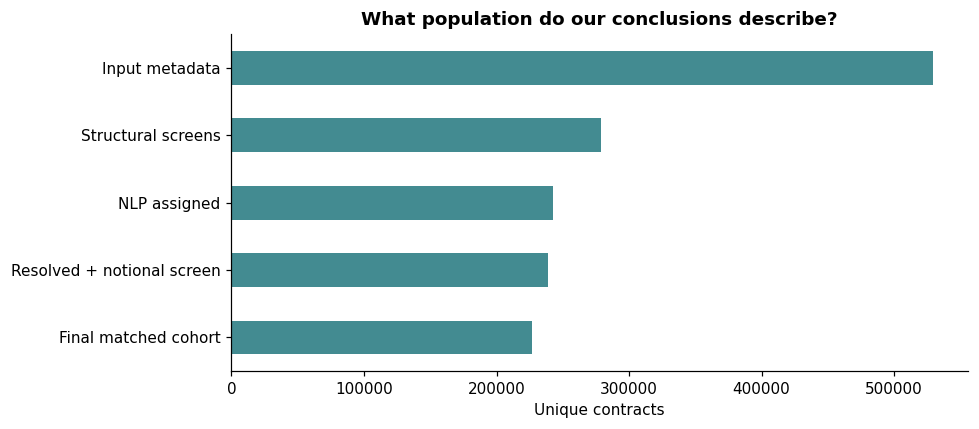

In [143]:
cells, audit = extract(DATA, ASSIGNMENTS, OUTPUT)
frame = cells[cells.assignment_status.eq("assigned") & cells.cluster.ne("")].copy()
resolved_assigned = frame.ticker.nunique()
excluded = contracts.loc[combination_mask(contracts), "ticker"]
frame = frame[~frame.ticker.isin(excluded)].copy()
support = (
    frame[frame.split.eq("train")]
    .groupby("cluster")
    .agg(contracts=("ticker", "nunique"), events=("event_id", "nunique"))
)
supported = support.index[support.contracts.ge(100) & support.events.ge(20)]
frame = frame[frame.cluster.isin(supported)].reset_index(drop=True)
validate_splits(frame)
if set(frame.split) != set(SPLITS):
    raise ValueError("The prediction cohort needs all three splits.")
# Verify cell labels and event IDs against the actual split CSV metadata.
labels = frame[["ticker", "event_id", "split", "family", "cluster"]].drop_duplicates()
checked = labels.merge(
    assignments[["ticker", "event_ticker", "split", "family", "cluster"]],
    on="ticker",
    how="left",
    validate="one_to_one",
    suffixes=("", "_csv"),
)
if not (
    checked.event_id.eq(checked.event_ticker).all()
    and all(checked[c].eq(checked[c + "_csv"]).all() for c in ["split", "family", "cluster"])
):
    raise ValueError("Cell labels disagree with supplied CSV split membership or assignments.")
frame["price"] = frame.p / 100
frame["residual"] = frame.outcome - frame.price
population = (
    frame.groupby("split")
    .agg(
        contracts=("ticker", "nunique"),
        events=("event_id", "nunique"),
        clusters=("cluster", "nunique"),
        executions=("n", "sum"),
    )
    .reindex(SPLITS)
)
population.to_csv(OUTPUT / "population.csv")
(OUTPUT / "data_audit.json").write_text(json.dumps(audit, indent=2) + "\n")
display(population)
display(pd.Series(audit).to_frame("audit"))
attrition_counts = pd.Series(
    {
        "Input metadata": int(input_counts.sum()),
        "Structural screens": len(contracts),
        "NLP assigned": int(assignments.status.eq("assigned").sum()),
        "Resolved + notional screen": resolved_assigned,
        "Final matched cohort": frame.ticker.nunique(),
    }
)
fig, ax = plt.subplots(figsize=(9, 4))
attrition_counts.iloc[::-1].plot.barh(ax=ax, color="#438b91")
ax.set(title="What population do our conclusions describe?", xlabel="Unique contracts", ylabel="")
show_figure("05_population_funnel")
del cells, checked

**Reading the dataset chart:** each bar shows how many unique contracts remain after a step. Shorter bars mean we have narrowed the sample. The last bar is the set used by every model. Keep this in mind when reading the results: they apply to the supported contracts that passed these checks.

## 5. Build on Becker's mispricing measure

Becker measures mispricing for a set of positions as its realized win rate minus its average purchase-implied probability (2026, *The Microstructure of Wealth Transfer in Prediction Markets*, Section 3, Equation 1). With price $p_i$ written as a probability and outcome $y_i$ equal to 0 or 1, this is:

$$\delta_S = \frac{1}{|S|}\sum_{i\in S}(y_i-p_i)$$

We use the same outcome-minus-price idea for YES positions. Each observation has a residual:

$$r_i = y_i-p_i$$

A 30-cent contract that settles YES has a residual of $+0.70$. If it settles NO, its residual is $-0.30$. Becker's group-level measure is the average of these residuals, not the error on one contract. One large error does not prove mispricing: even a well-priced unlikely event will sometimes happen.

Our extension changes **which contracts we group together** and asks whether those groups help predict the residual. Since our rows summarize repeated executions at the same contract and price, we weight each row by its execution count $n_i$. For a group $G$, the measure becomes:

$$\delta_G = \frac{\sum_{i\in G} n_i r_i}{\sum_{i\in G} n_i}$$

This gives the same average as counting each represented execution once. Multiplying by 100 expresses the result in percentage points. A positive group average means YES paid out more often than prices implied; a negative average means it paid out less often.

We focus on this YES-side calibration measure. We do not reproduce Becker's maker/taker decomposition or his YES-versus-NO comparison at equal purchase costs. Our $r_i$ is a probability residual, not a return on money invested.

The next plots use training data only. The left plot compares average prices with win rates. The right plot applies this group-average residual within family/price bands for the eight families with the most training executions. We hide cells with fewer than five training events to avoid showing averages based on very little support.

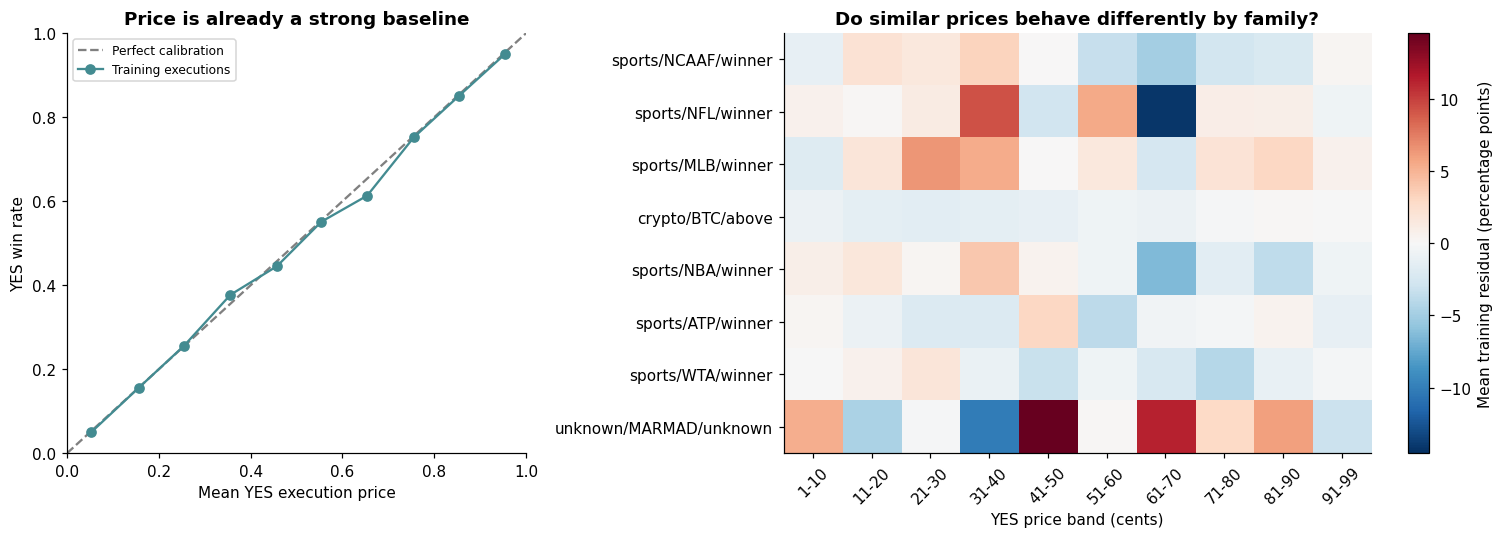

In [144]:
train = frame[frame.split.eq("train")].copy()
train["bucket"] = (train.p.astype(int) - 1) // 10
train["wins"] = train.n * train.outcome
train["price_total"] = train.n * train.price
train["residual_total"] = train.n * train.residual
calibration = train.groupby("bucket").agg(n=("n", "sum"), wins=("wins", "sum"), price_total=("price_total", "sum"))
calibration["mean_price"] = calibration.price_total / calibration.n
calibration["win_rate"] = calibration.wins / calibration.n
largest_families = train.groupby("family").n.sum().nlargest(8).index
family_bins = (
    train[train.family.isin(largest_families)]
    .groupby(["family", "bucket"])
    .agg(n=("n", "sum"), residual_total=("residual_total", "sum"), events=("event_id", "nunique"))
)
family_bins["deviation_pp"] = 100 * family_bins.residual_total / family_bins.n
heat = (
    family_bins.deviation_pp.where(family_bins.events.ge(5))
    .unstack()
    .reindex(index=largest_families, columns=range(10))
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
axes[0].plot(calibration.mean_price, calibration.win_rate, "o-", color="#438b91", label="Training executions")
axes[0].set(
    title="Price is already a strong baseline",
    xlabel="Mean YES execution price",
    ylabel="YES win rate",
    xlim=(0, 1),
    ylim=(0, 1),
)
axes[0].legend(fontsize=8)
limit = max(1, float(np.nanmax(np.abs(heat.to_numpy()))))
image = axes[1].imshow(heat, aspect="auto", cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit))
axes[1].set_xticks(range(10), [f"{10 * i + 1}-{min(99, 10 * i + 10)}" for i in range(10)], rotation=45)
axes[1].set_yticks(range(len(heat)), heat.index)
axes[1].set(title="Do similar prices behave differently by family?", xlabel="YES price band (cents)")
plt.colorbar(image, ax=axes[1], label="Mean training residual (percentage points)")
show_figure("06_training_calibration")

**Reading the training plots:** on the left, points near the diagonal mean average prices are close to observed win rates. Points above it suggest YES paid out more often than the prices implied; points below suggest the opposite.

In the heatmap, red means the average YES outcome was higher than the price implied, and blue means it was lower. Columns compare similar price ranges. Different colors within a column suggest differences between families worth investigating. These are training patterns, though, so they only motivate the model; they do not show that the patterns will hold on the test set.

## 6. Add group membership to one shared model

We use ridge regression for all three comparisons, with a fixed regularization setting of $\alpha=10$. Ridge limits large coefficients, which helps keep the model from making overly large adjustments based on the training data.

| Comparison | Features given to the model |
|---|---|
| Pooled | Price, price squared, and price cubed |
| Structural | The same price terms, plus structural family |
| Structural + NLP | The same price terms, plus family and NLP cluster |

**Pooled is the main modeling baseline.** Comparing the grouped models with pooled tells us whether membership adds useful information. Market price is a separate benchmark with zero predicted correction; it is not one of the three fitted models.

Each row is one model trained on all training contracts, rather than a separate model for every group. We use one-hot encoding for family and cluster labels. This gives each category its own indicator column instead of treating cluster numbers as measurements.

The model predicts the pricing error. We add that prediction to the original price to get an adjusted YES probability, keeping the result between 0 and 1:

$$q = \mathrm{clip}(p+\widehat r,0,1)$$

We standardize the price features using training data and execution weights. Category indicators stay at 0 or 1. In this setup, groups can shift the predicted error up or down, but they do not get separate price curves. We keep the model settings fixed rather than searching for the best result on validation or test data.

In [145]:
FEATURE_SETS = {"Pooled": [], "Structural": ["family"], "Structural + NLP": ["family", "cluster"]}


def fit_comparisons(data: pd.DataFrame) -> tuple[pd.DataFrame, dict, pd.DataFrame]:
    """Three feature ablations of one ridge estimator, all fitted on training labels only."""
    validate_splits(data)
    training = data[data.split.eq("train")]
    held = data[~data.split.eq("train")].copy().reset_index(drop=True)
    weights = training.n.to_numpy(dtype=float)
    residual = training.outcome.to_numpy() - training.price.to_numpy()
    numeric_train = training.price.to_numpy()[:, None] ** np.arange(1, 4)
    numeric_held = held.price.to_numpy()[:, None] ** np.arange(1, 4)
    scaler = StandardScaler().fit(numeric_train, sample_weight=weights)
    base_train = sparse.csr_matrix(scaler.transform(numeric_train))
    base_held = sparse.csr_matrix(scaler.transform(numeric_held))
    held["Market price"] = held.price
    fitted, dimensions = {}, []
    for name, categories in FEATURE_SETS.items():
        x_train, x_held = base_train, base_held
        encoder = None
        if categories:
            encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
            encoded_train = encoder.fit_transform(training[categories])
            encoded_held = encoder.transform(held[categories])
            x_train = sparse.hstack([base_train, encoded_train], format="csr")
            x_held = sparse.hstack([base_held, encoded_held], format="csr")
        model = Ridge(alpha=ALPHA, solver="lsqr", tol=1e-8)
        model.fit(x_train, residual, sample_weight=weights / weights.mean())
        held[name] = np.clip(held.price.to_numpy() + model.predict(x_held), 0, 1)
        fitted[name] = {"model": model, "encoder": encoder, "scaler": scaler}
        dimensions.append(
            {"approach": name, "features": x_train.shape[1], "training_cells": len(training), "shared_models": 1}
        )
    return held, fitted, pd.DataFrame(dimensions)


with threadpool_limits(limits=2):
    predictions, fitted, model_sizes = fit_comparisons(frame)
display(model_sizes)
model_sizes.to_csv(OUTPUT / "model_sizes.csv", index=False)
predictions.to_parquet(OUTPUT / "heldout_predictions.parquet", index=False)

,approach,features,training_cells,shared_models
0,Pooled,3,3017654,1
1,Structural,95,3017654,1
2,Structural + NLP,381,3017654,1


### How much does each model change the price?

The histograms below show the predicted YES corrections on validation observations. They use the same bins and execution weights, so their shapes can be compared directly.

**Reading the charts:** zero means the model keeps the market price. A correction of +5 percentage points would move a 30% probability to 35%; a negative correction moves it down. A narrow distribution near zero means small adjustments, while a wider distribution means larger adjustments. The bar heights show the share of validation executions in each bin.

These plots show what the models do. They do not tell us whether the changes are correct, since we have not used validation outcomes in this chart.

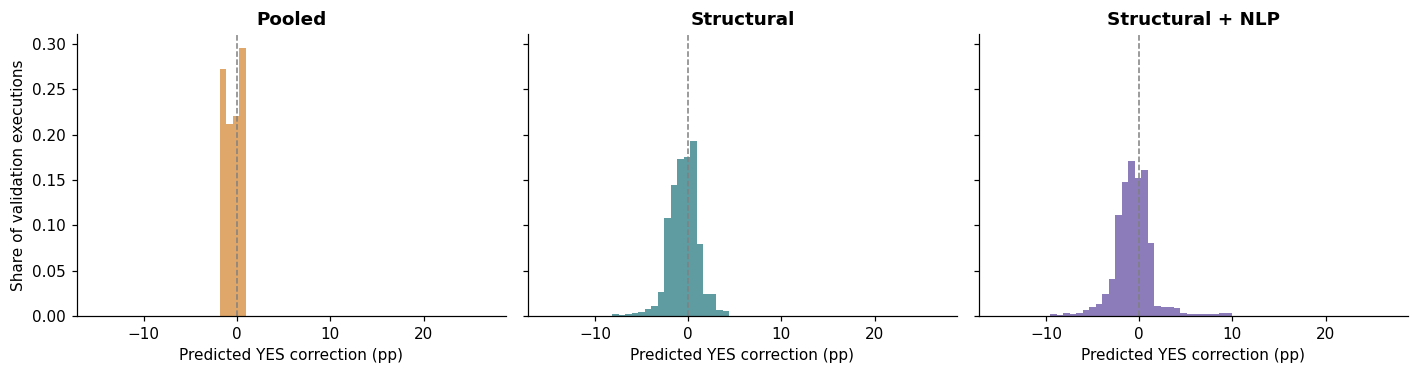

In [146]:
validation = predictions[predictions.split.eq("validation")]
corrections = 100 * validation[list(FEATURE_SETS)].sub(validation.price, axis=0)
common_bins = np.linspace(corrections.to_numpy().min(), corrections.to_numpy().max(), 61)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharex=True, sharey=True)
for ax, name in zip(axes, FEATURE_SETS):
    correction = corrections[name]
    ax.hist(correction, bins=common_bins, weights=validation.n / validation.n.sum(), color=COLORS[name], alpha=0.85)
    ax.axvline(0, color="gray", linestyle="--", linewidth=1)
    ax.set(title=name, xlabel="Predicted YES correction (pp)")
axes[0].set_ylabel("Share of validation executions")
show_figure("07_model_corrections")

## 7. Check whether the adjustments actually help

Becker's metric tells us how a group was priced relative to its realized outcomes. Our main prediction question is whether adding group membership helps a model predict those errors on held-out events, compared with a pooled model that has no group information. We also check whether pooled recalibration improves on the original market price. We compare the models with **Brier score**, the average squared difference between predicted probability and final outcome. Each row is weighted by its number of executions:

$$\mathrm{Brier}=\frac{\sum_i n_i(y_i-q_i)^2}{\sum_i n_i}$$

Brier score is our evaluation measure, not a replacement definition of mispricing. If $\widehat r_i=q_i-p_i$ is the model's final residual prediction, then:

$$(y_i-q_i)^2 = \big[(y_i-p_i)-(q_i-p_i)\big]^2 = (r_i-\widehat r_i)^2$$

So scoring the adjusted probability is also scoring how accurately we predicted the outcome-minus-price residual.

**Lower is better.** The pooled model is the main modeling baseline. The market-price benchmark uses the original YES price without a correction, so it represents making no fitted adjustment to the market forecast. Every approach is scored on the same observations. We show validation scores as a separate check, but use test scores for the main comparison.

In the test-score plot, points farther left have lower error. The dashed line marks pooled, our main modeling baseline. A grouped model needs to fall to its left to improve on pooling. The dotted line marks the separate market-price benchmark, showing whether a model also improves on the uncorrected price. The labels show the exact scores because the differences can be small. This plot shows the size of the differences; the next step checks their uncertainty.

split,test,validation
approach,,
Market price,0.171318,0.169457
Pooled,0.171333,0.169913
Structural,0.171763,0.169833
Structural + NLP,0.171939,0.169859


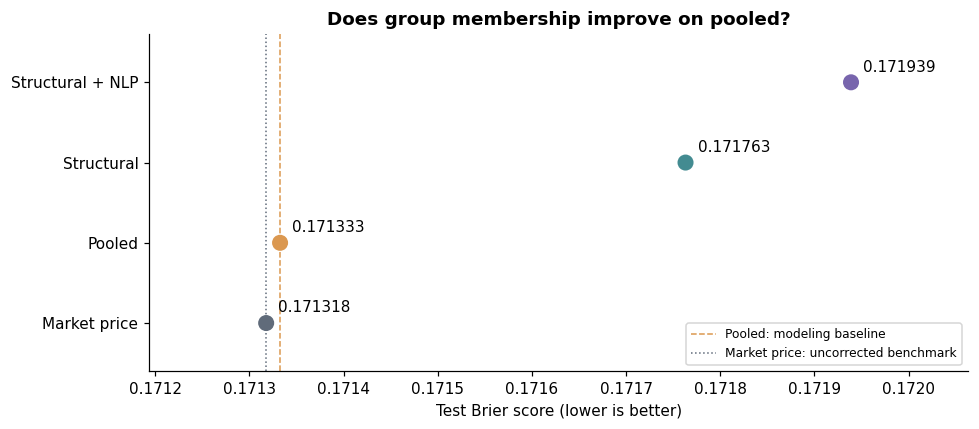

In [147]:
score_rows = []
for split, held in predictions.groupby("split"):
    for name in COLORS:
        brier = np.average((held.outcome - held[name]) ** 2, weights=held.n)
        score_rows.append({"split": split, "approach": name, "brier": brier})
scores = pd.DataFrame(score_rows)
scores.to_csv(OUTPUT / "scores.csv", index=False)
display(scores.pivot(index="approach", columns="split", values="brier").reindex(COLORS))
test_scores = scores[scores.split.eq("test")].set_index("approach").reindex(COLORS)
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(test_scores.brier, test_scores.index, s=90, c=[COLORS[n] for n in test_scores.index])
for name, row in test_scores.iterrows():
    ax.annotate(f"{row.brier:.6f}", (row.brier, name), xytext=(8, 7), textcoords="offset points")
ax.axvline(
    test_scores.loc["Pooled", "brier"],
    color=COLORS["Pooled"],
    linestyle="--",
    linewidth=1,
    label="Pooled: modeling baseline",
)
ax.axvline(
    test_scores.loc["Market price", "brier"],
    color=COLORS["Market price"],
    linestyle=":",
    linewidth=1,
    label="Market price: uncorrected benchmark",
)
ax.legend(fontsize=8, loc="best")
ax.margins(x=0.2, y=0.2)
ax.set(title="Does group membership improve on pooled?", xlabel="Test Brier score (lower is better)")
show_figure("08_test_scores")

### Are the score differences clear enough to draw a conclusion?

Trades from one event are related, so treating every trade as independent would give us too much confidence. We use an event bootstrap: repeatedly sample whole test events, keeping each event's trades together, and recalculate the difference in scores.

We report four comparisons, with the grouping question first:

1. **Structural versus pooled:** does structural membership help?
2. **Structural + NLP versus pooled:** does the full grouping approach help compared with no grouping?
3. **Structural + NLP versus structural:** does NLP add anything beyond structural membership?
4. **Pooled versus market price:** a separate benchmark check asking whether global recalibration helps at all.

The first two use pooled as the main modeling baseline. The third isolates the additional contribution of NLP. Comparing only with the parent would miss the direct comparison between the full grouping approach and pooled. Improvement is the baseline Brier score minus the candidate Brier score, so **positive values mean the candidate helped**.

**Reading the interval plot:** the dot is the observed improvement and the line is its 95% bootstrap interval. An interval entirely to the right of zero favors the candidate. An interval entirely to the left favors the baseline. If it crosses zero, the comparison is inconclusive under this check.

These intervals are exploratory and are not adjusted for testing several comparisons. They also assume our fitted groups and models are fixed. They do not include the uncertainty from learning those groups again or account for every possible relationship between different events.

,candidate,baseline,improvement,ci_low,ci_high,events
0,Structural,Pooled,-0.000430,-0.000690,-0.000177,8545
1,Structural + NLP,Pooled,-0.000606,-0.000914,-0.000311,8545
2,Structural + NLP,Structural,-0.000176,-0.000357,0.000001,8545
3,Pooled,Market price,-0.000015,-0.000374,0.000362,8545


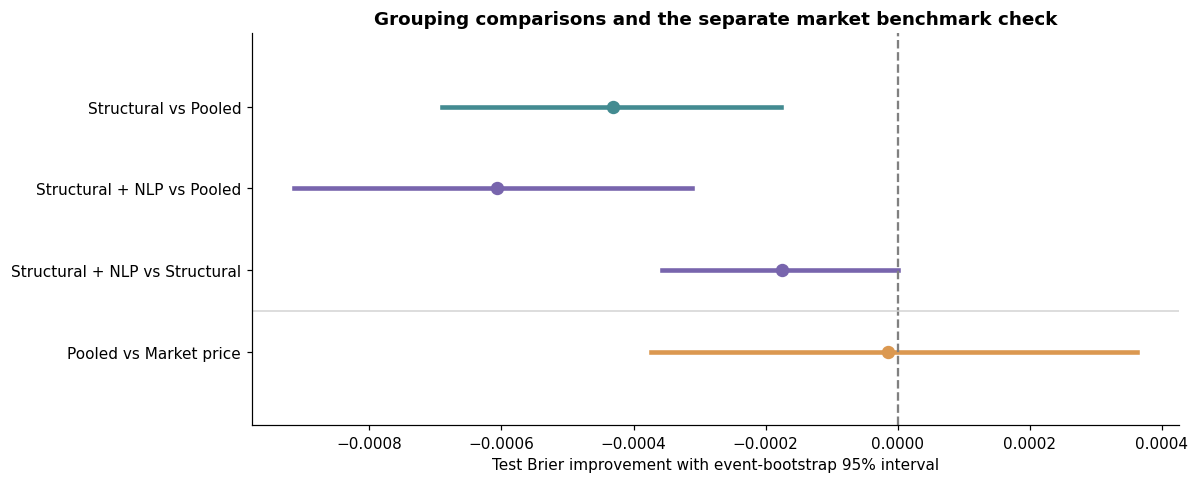

In [148]:
def compare_by_event(held: pd.DataFrame, candidate: str, baseline: str, repetitions: int) -> dict:
    """Bootstrap the paired loss difference using whole-event weighted totals."""
    difference = (held.outcome - held[baseline]) ** 2 - (held.outcome - held[candidate]) ** 2
    blocks = (
        pd.DataFrame({"event": held.event_id, "numerator": held.n * difference, "weight": held.n})
        .groupby("event")[["numerator", "weight"]]
        .sum()
        .to_numpy()
    )
    if len(blocks) < 2:
        raise ValueError("Need at least two held-out events for uncertainty.")
    rng = np.random.default_rng(SEED)
    draws = np.empty(repetitions)
    for i in range(repetitions):
        total = blocks[rng.integers(len(blocks), size=len(blocks))].sum(axis=0)
        draws[i] = total[0] / total[1]
    low, high = np.quantile(draws, [0.025, 0.975])
    return {
        "candidate": candidate,
        "baseline": baseline,
        "improvement": blocks[:, 0].sum() / blocks[:, 1].sum(),
        "ci_low": low,
        "ci_high": high,
        "events": len(blocks),
    }


test = predictions[predictions.split.eq("test")].copy()
pairs = [
    ("Structural", "Pooled"),
    ("Structural + NLP", "Pooled"),
    ("Structural + NLP", "Structural"),
    ("Pooled", "Market price"),
]
comparisons = pd.DataFrame([compare_by_event(test, candidate, baseline, BOOTSTRAP) for candidate, baseline in pairs])
comparisons.to_csv(OUTPUT / "comparisons.csv", index=False)
display(comparisons)
fig, ax = plt.subplots(figsize=(11, 4.5))
for i, row in comparisons.iterrows():
    ax.plot([row.ci_low, row.ci_high], [i, i], color=COLORS[row.candidate], linewidth=3)
    ax.scatter(row.improvement, i, color=COLORS[row.candidate], s=60, zorder=3)
ax.axvline(0, color="gray", linestyle="--")
ax.set_yticks(range(len(comparisons)), comparisons.candidate + " vs " + comparisons.baseline)
ax.axhline(2.5, color="lightgray", linewidth=1)
ax.invert_yaxis()
ax.margins(y=0.3)
ax.set(
    title="Grouping comparisons and the separate market benchmark check",
    xlabel="Test Brier improvement with event-bootstrap 95% interval",
)
show_figure("09_incremental_value")

### Do the models work better in the best-supported clusters?

Some NLP clusters have much more training support than others. As a small check, we rank the eligible clusters by **distinct training events**, then evaluate the existing predictions in the top 10, 25, and 50 clusters. Ties are broken by cluster ID, so test results do not affect membership. We also keep the full eligible sample for comparison.

We do not retrain the models or change the clustering. Within each subset, pooled, structural, NLP, and market-price predictions are scored on the same test executions. We rank by events rather than trades because many executions can share one event outcome. Even the full eligible set already requires at least 100 resolved training contracts and 20 training events per cluster.

**Reading the figure:** the left panel shows the share of test executions retained. The right panel shows each grouped model's improvement over pooled within that same subset. Above zero means grouping helped; below zero means it hurt. Compare each point with zero rather than comparing raw Brier scores across subsets, since the subsets contain different topics and price distributions.

This is a descriptive check, with no additional significance tests or model selection. If the larger clusters perform better, that would motivate further investigation, but would not prove sample size caused the difference.

,training_clusters,min_training_events,test_clusters,test_contracts,test_events,test_execution_pct
subset,,,,,,
Top 10,10,502,10,7136,2137,35.395665
Top 25,25,314,25,14528,3551,41.488510
Top 50,50,257,50,18484,4458,49.482099
All eligible,286,20,286,45619,8545,100.000000


approach,Market price,Pooled,Structural,Structural + NLP
subset,,,,
Top 10,0.161751,0.162093,0.162295,0.162169
Top 25,0.161241,0.161610,0.161785,0.161693
Top 50,0.163662,0.163961,0.164128,0.164082
All eligible,0.171318,0.171333,0.171763,0.171939


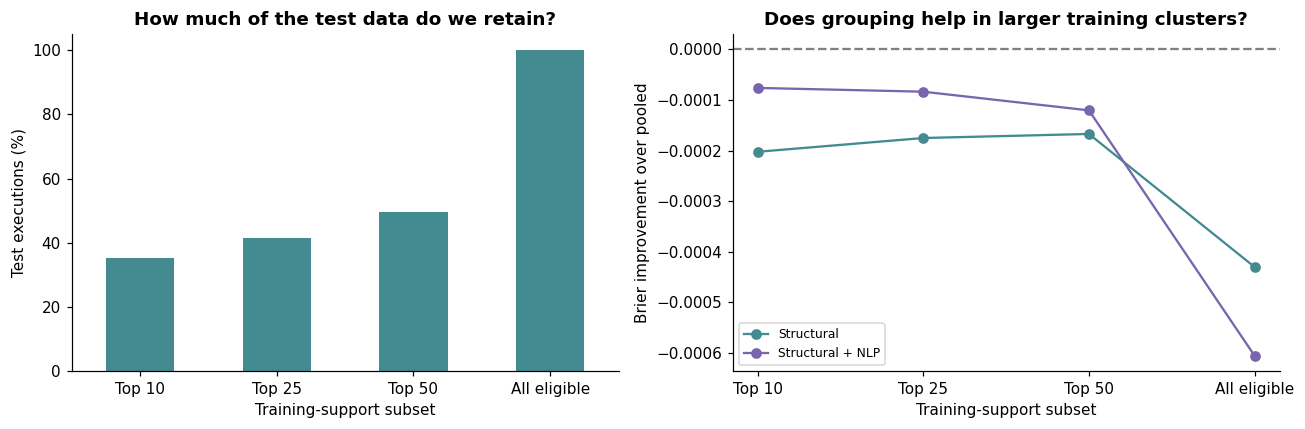

In [149]:
top_k_values = [10, 25, 50]
cluster_rank = (
    frame[frame.split.eq("train")]
    .groupby("cluster")
    .agg(training_events=("event_id", "nunique"), training_contracts=("ticker", "nunique"))
    .reset_index()
    .sort_values(["training_events", "cluster"], ascending=[False, True])
)
cluster_rank.to_csv(OUTPUT / "cluster_training_support_ranked.csv", index=False)
subsets = [(f"Top {k}", k) for k in top_k_values] + [("All eligible", len(cluster_rank))]
top_k_rows = []
for label, k in subsets:
    chosen = cluster_rank.head(k)
    subset = test[test.cluster.isin(chosen.cluster)]
    if subset.empty:
        continue
    pooled_brier = np.average((subset.outcome - subset["Pooled"]) ** 2, weights=subset.n)
    for name in COLORS:
        brier = np.average((subset.outcome - subset[name]) ** 2, weights=subset.n)
        top_k_rows.append(
            {
                "subset": label,
                "approach": name,
                "brier": brier,
                "improvement_vs_pooled": pooled_brier - brier,
                "training_clusters": len(chosen),
                "min_training_events": int(chosen.training_events.min()),
                "test_clusters": subset.cluster.nunique(),
                "test_contracts": subset.ticker.nunique(),
                "test_events": subset.event_id.nunique(),
                "executions": int(subset.n.sum()),
                "test_execution_pct": 100 * subset.n.sum() / test.n.sum(),
            }
        )
top_k_results = pd.DataFrame(top_k_rows)
top_k_results.to_csv(OUTPUT / "top_k_results.csv", index=False)
subset_order = [label for label, _ in subsets if label in top_k_results.subset.values]
top_k_coverage = top_k_results.drop_duplicates("subset").set_index("subset").reindex(subset_order)
display(
    top_k_coverage[
        [
            "training_clusters",
            "min_training_events",
            "test_clusters",
            "test_contracts",
            "test_events",
            "test_execution_pct",
        ]
    ]
)
display(
    top_k_results.pivot(index="subset", columns="approach", values="brier").reindex(
        index=subset_order, columns=list(COLORS)
    )
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
top_k_coverage.test_execution_pct.plot.bar(ax=axes[0], color="#438b91", rot=0)
axes[0].set(
    title="How much of the test data do we retain?",
    xlabel="Training-support subset",
    ylabel="Test executions (%)",
    ylim=(0, 105),
)
gains = top_k_results.pivot(index="subset", columns="approach", values="improvement_vs_pooled").reindex(subset_order)
for name in ["Structural", "Structural + NLP"]:
    axes[1].plot(range(len(subset_order)), gains[name], "o-", color=COLORS[name], label=name)
axes[1].set_xticks(range(len(subset_order)), subset_order)
axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set(
    title="Does grouping help in larger training clusters?",
    xlabel="Training-support subset",
    ylabel="Brier improvement over pooled",
)
axes[1].legend(fontsize=8)
show_figure("11_top_k_clusters")

## 8. Check whether the predicted probabilities make sense

The final figure compares average predicted YES probabilities with observed YES win rates. We group each model's test predictions into probability bins and weight them by execution count.

**Reading the reliability plot:** a point on the diagonal means the average prediction matches the win rate in that bin. Points above the line mean YES happened more often than predicted; points below it mean YES happened less often. Curves close to the diagonal suggest good calibration at this level of grouping.

The curves can look very similar even when their Brier scores differ. This plot averages over bins, while Brier score evaluates every prediction. We use it to help explain the results, not to choose new model settings.

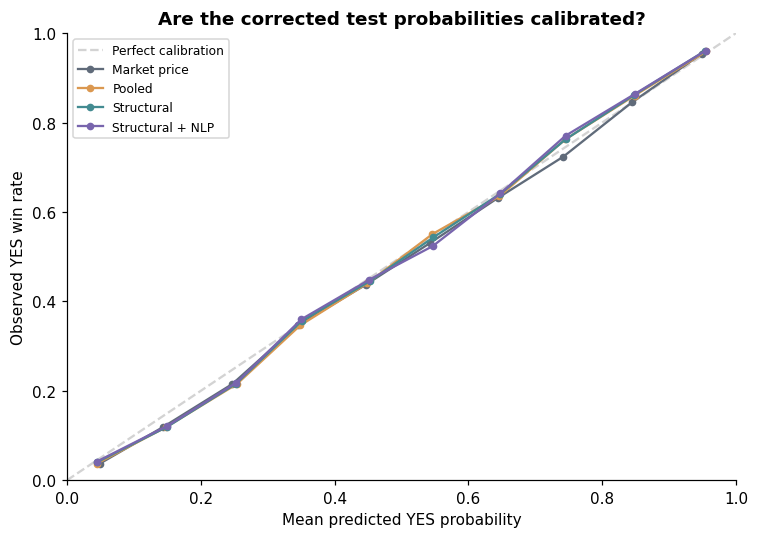

In [150]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot([0, 1], [0, 1], "--", color="lightgray", label="Perfect calibration")
for name, color in COLORS.items():
    reliability = pd.DataFrame(
        {
            "bin": np.minimum((test[name] * 10).astype(int), 9),
            "weight": test.n,
            "predicted": test.n * test[name],
            "observed": test.n * test.outcome,
        }
    )
    reliability = reliability.groupby("bin")[["weight", "predicted", "observed"]].sum()
    ax.plot(
        reliability.predicted / reliability.weight,
        reliability.observed / reliability.weight,
        "o-",
        markersize=4,
        color=color,
        label=name,
    )
ax.set(
    title="Are the corrected test probabilities calibrated?",
    xlabel="Mean predicted YES probability",
    ylabel="Observed YES win rate",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.legend(fontsize=8)
show_figure("10_test_reliability")

## 9. What did we learn?

Becker establishes the broader finding of mispricing across the dataset. Our extension asks whether looking at finer groups helps explain that variation and improve predictions. The training heatmap shows how average pricing errors differ across families; the held-out scores test whether adding family and cluster membership helps the model predict those errors. Compare both grouped models directly with pooled, then compare NLP clusters with structural families to isolate the extra contribution of text grouping. Finally, use pooled versus market price as a separate benchmark check.

The summary below uses this run's results. A positive improvement means a lower Brier score, but we also need to look at its interval before drawing a conclusion. An improvement over pooled would support using group membership in this model. It would not automatically establish an improvement over the uncorrected market benchmark, which is a separate question.

In [151]:
conclusions = []
for heading, subset in [
    ("### Grouping comparisons", comparisons[comparisons.baseline.ne("Market price")]),
    ("### Separate market benchmark check", comparisons[comparisons.baseline.eq("Market price")]),
]:
    conclusions.append(heading)
    for row in subset.itertuples(index=False):
        if row.ci_low > 0:
            interpretation = "the interval is above zero, suggesting the candidate helped"
        elif row.ci_high < 0:
            interpretation = "the interval is below zero, suggesting the candidate made predictions worse"
        else:
            interpretation = "the interval includes zero, so we do not have a clear difference here"
        conclusions.append(
            f"- **{row.candidate} versus {row.baseline}:** Brier improvement {row.improvement:+.6f}; {interpretation}."
        )
    conclusions.append("")
display(Markdown("\n".join(conclusions)))
(OUTPUT / "conclusions.md").write_text("\n".join(conclusions) + "\n")

### Grouping comparisons
- **Structural versus Pooled:** Brier improvement -0.000430; the interval is below zero, suggesting the candidate made predictions worse.
- **Structural + NLP versus Pooled:** Brier improvement -0.000606; the interval is below zero, suggesting the candidate made predictions worse.
- **Structural + NLP versus Structural:** Brier improvement -0.000176; the interval includes zero, so we do not have a clear difference here.

### Separate market benchmark check
- **Pooled versus Market price:** Brier improvement -0.000015; the interval includes zero, so we do not have a clear difference here.


621

### What these results mean for our project

This experiment tests whether family and cluster labels help a shared ridge model on the supplied event splits. If the grouped models do not improve on pooled, the conclusion is that **these group features did not help this model on this sample**. The separate comparison of pooled with market price tells us whether fitting a global correction was useful in the first place. That is still a useful result; grouping contracts in a reasonable way does not guarantee better predictions.

This result does not contradict Becker's finding of mispricing across the dataset. Finding historical mispricing and predicting it on held-out events are different tasks. Our grouped models could fail to improve predictions even if pricing errors vary across groups. The result also does not prove that all markets are efficient, that the groups have no value, or that another prediction method could not work better.

There are also limits to the study. Our structural rules do not recognize every contract type, the text comes from a collected snapshot, and related outcomes may appear under different event IDs. We have also used this dataset while developing earlier versions of the method, so this is an exploratory result rather than a test on completely new data.

A next step would be to freeze the method and evaluate it on a later sample, checking that training outcomes were known before making each prediction. For this project, we are reporting prediction accuracy across held-out events. We have not tested a 72-hour forecast or a trading strategy after fees.

In [152]:
notebook_path = ROOT / "extension/notebooks/main.ipynb"
notebook = json.loads(notebook_path.read_text())
authored = [(c["cell_type"], "".join(c["source"])) for c in notebook["cells"]]
manifest = {
    "completed": True,
    "seed": SEED,
    "ridge_alpha": ALPHA,
    "bootstrap": BOOTSTRAP,
    "feature_sets": FEATURE_SETS,
    "comparison_pairs": pairs,
    "top_k_training_event_subsets": top_k_values,
    "grouping": vars(GROUPING),
    "inputs": [{"path": str(p), "bytes": p.stat().st_size, "mtime_ns": p.stat().st_mtime_ns} for p in required],
    "versions": {
        p: importlib.metadata.version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "duckdb", "matplotlib"]
    },
    "notebook_sha256": hashlib.sha256(json.dumps(authored).encode()).hexdigest(),
    "elapsed_seconds": time.time() - started,
}
(OUTPUT / "run_manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
print(f"Completed in {manifest['elapsed_seconds'] / 60:.1f} minutes. Tables, predictions, and 11 figures: {OUTPUT}")

Completed in 4.2 minutes. Tables, predictions, and 11 figures: /Users/colekvasnak/Documents/School/DS 340W/prediction-market-analysis/output/extension_notebook_simple
